# Partie 2 — Génération d’images et variables latentes
**Binôme : Amjad AAYD et [information masquée] — [information masquée] — 6 octobre 2026**

Enseignant : [information masquée]. Groupe : à compléter.
Source : Introduction aux modèles génératifs, huit pages, 20 avril 2026. Résultats exécutés, graines fixées.


In [1]:
%matplotlib inline
import sys, json, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import sklearn
from IPython.display import display
np.set_printoptions(precision=5, suppress=True)
torch.set_default_dtype(torch.float64)
torch.set_num_threads(2)
torch.manual_seed(43)
rng = np.random.default_rng(43)
figdir = Path("figures")
figdir.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .2})
def save(fig, name):
    fig.savefig(figdir / (name + ".png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)
print("Python", sys.version.split()[0], "| NumPy", np.__version__, "| PyTorch", torch.__version__, "| scikit-learn", sklearn.__version__)
print("Calcul CPU, float64, deux threads ; graine =", 43)


Python 3.12.10 | NumPy 2.3.5 | PyTorch 2.12.0.dev20260408+cu128 | scikit-learn 1.8.0
Calcul CPU, float64, deux threads ; graine = 43


## 2.1 Données, moyenne et covariance /N
Le choix autorisé est `load_digits` : 1 797 images de chiffres en niveaux de gris, taille 8×8, intensités entières 0 à 16. On prend les 1 500 premières images comme sous-ensemble d'apprentissage et on divise par 16. Chaque image est un vecteur de dimension 64. Le reste n'est pas utilisé pour ajuster le modèle ; le TP porte sur une comparaison visuelle, sans mesure de généralisation.

μ̂ = moyenne(X), Σ̂ = (X−μ̂)ᵀ(X−μ̂)/N. Ce diviseur suit le sujet. La covariance est symétrique semi-définie positive : certains pixels toujours noirs impliquent des directions de variance nulle. On n'impose donc pas une covariance strictement définie positive dans cette partie.

Données : 1500 images, dimension 64 ; rang numérique 61
Variance conservée : {10: 0.739196, 25: 0.933613, 50: 0.999511}


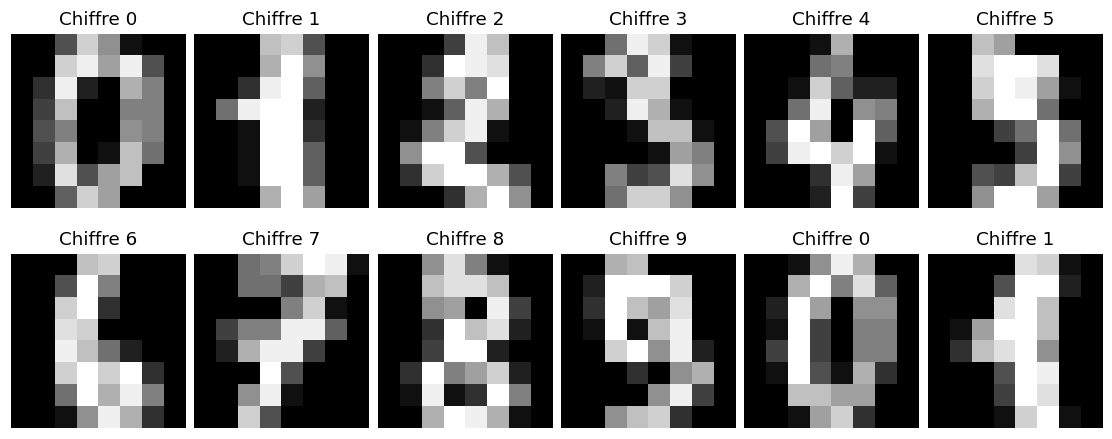

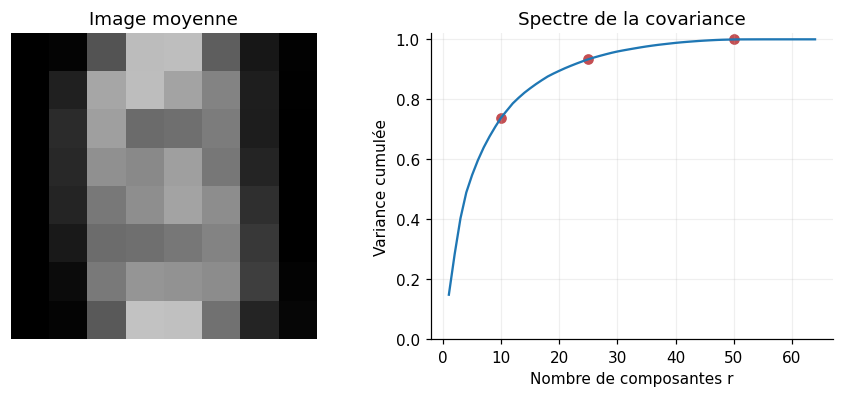

In [2]:
from sklearn.datasets import load_digits
digits=load_digits()
Ximg=digits.data[:1500].astype(np.float64)/16.
labels=digits.target[:1500]
N,d=Ximg.shape
mu_img=Ximg.mean(axis=0);centered=Ximg-mu_img
cov_img=centered.T@centered/N
evals,E=np.linalg.eigh(cov_img);order=np.argsort(evals)[::-1];evals=evals[order];E=E[:,order]
assert (N,d)==(1500,64)
assert np.allclose(cov_img,cov_img.T)
assert evals.min()>-1e-10
# Seuls les très petits négatifs dus à l'arrondi sont ramenés à zéro.
evals=np.maximum(evals,0)
assert np.allclose(E@np.diag(evals)@E.T,cov_img,atol=1e-10)
cumulative=np.cumsum(evals)/evals.sum()
print('Données :',N,'images, dimension',d,'; rang numérique',np.sum(evals>1e-10))
print('Variance conservée :',{r:round(float(cumulative[r-1]),6) for r in [10,25,50]})
fig,ax=plt.subplots(2,6,figsize=(10,4),layout='constrained')
for i,a in enumerate(ax.flat):
    a.imshow(Ximg[i].reshape(8,8),cmap='gray',vmin=0,vmax=1,interpolation='nearest');a.set_title(f'Chiffre {labels[i]}');a.axis('off')
save(fig,'08_images_reelles')
fig,ax=plt.subplots(1,2,figsize=(8,3.5),layout='constrained')
ax[0].imshow(mu_img.reshape(8,8),cmap='gray',vmin=0,vmax=1,interpolation='nearest');ax[0].set_title('Image moyenne');ax[0].axis('off')
ax[1].plot(np.arange(1,65),cumulative);ax[1].scatter([10,25,50],cumulative[[9,24,49]],color='#c44e52');ax[1].set(xlabel='Nombre de composantes r',ylabel='Variance cumulée',ylim=(0,1.02),title='Spectre de la covariance')
save(fig,'09_moyenne_variance')


### Directions principales (eigen-images)
Les colonnes de E sont des directions signées ; elles ne sont pas des images ordinaires de chiffres. Une palette divergente centrée sur zéro montre où une direction augmente ou diminue l'intensité. Le signe d'un vecteur propre est arbitraire ; changer simultanément le signe de la coordonnée latente correspondante ne change pas le modèle.

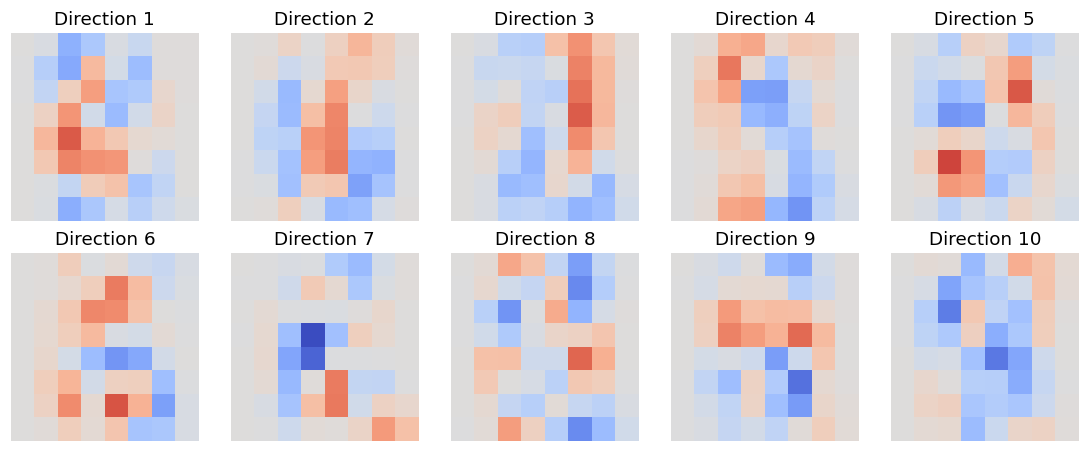

In [3]:
fig,ax=plt.subplots(2,5,figsize=(10,4),layout='constrained')
bound=float(np.max(np.abs(E[:,:10])))
for j,a in enumerate(ax.flat):
    a.imshow(E[:,j].reshape(8,8),cmap='coolwarm',vmin=-bound,vmax=bound,interpolation='nearest');a.set_title(f'Direction {j+1}');a.axis('off')
save(fig,'10_eigen_images')


### Générer avec r=10,25,50
Aᵣ = Eᵣ diag(√λ₁,…,√λᵣ), et G(z)=μ̂+Aᵣz, avec z∼N(0,Iᵣ). On partage les mêmes 50 coordonnées de base entre les trois essais pour que la comparaison ne soit pas dominée par de nouveaux tirages aléatoires. Les sorties brutes peuvent être hors [0,1] : les images affichées sont clippées, mais les tests de moyenne/covariance utilisent le modèle brut. Plus de composantes conserve plus de variation, sans garantir des chiffres plus réalistes.

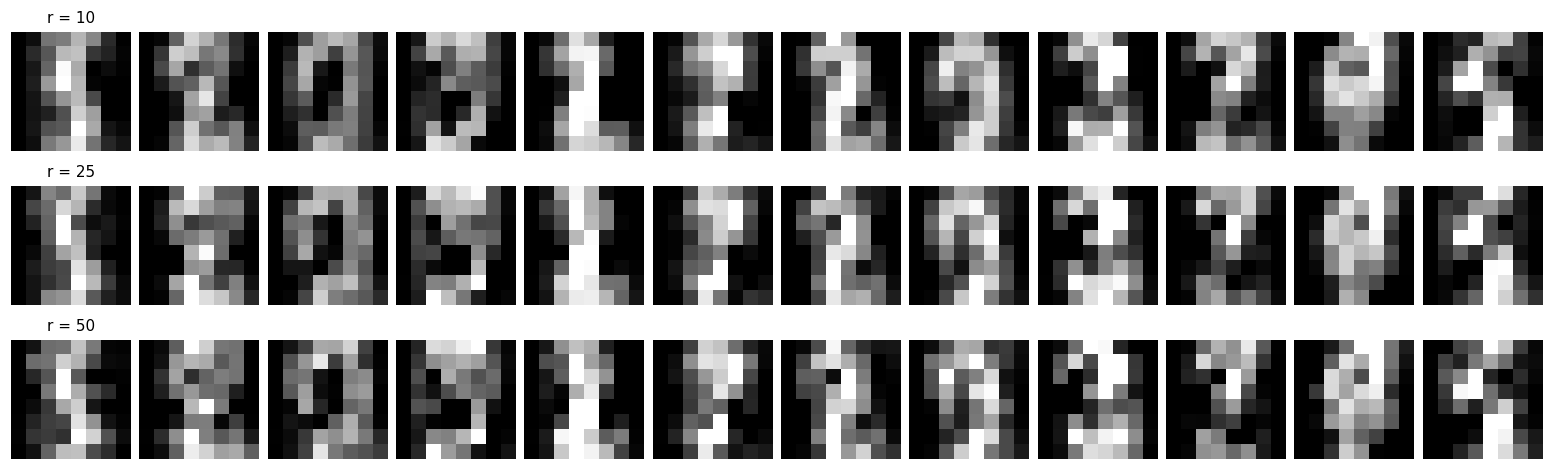

Pixels bruts hors [0,1] pour ces douze échantillons : {10: 0.19661458333333334, 25: 0.21875, 50: 0.2526041666666667}
Vérification Monte-Carlo r=25 : erreur moyenne L2 0.015285979227941138 ; erreur covariance relative 0.020915680146033157


In [4]:
Z=rng.standard_normal((12,50));generated={};outside={}
fig,ax=plt.subplots(3,12,figsize=(14,4.2),layout='constrained')
for row,r in enumerate([10,25,50]):
    A=E[:,:r]*np.sqrt(evals[:r])[None,:]
    raw=mu_img+Z[:,:r]@A.T
    generated[r]=raw
    outside[r]=float(np.mean((raw<0)|(raw>1)))
    assert np.allclose(A@A.T,(E[:,:r]*evals[:r])@E[:,:r].T)
    for j in range(12):
        ax[row,j].imshow(np.clip(raw[j],0,1).reshape(8,8),cmap='gray',vmin=0,vmax=1,interpolation='nearest');ax[row,j].axis('off')
        if j==0:ax[row,j].set_title(f'r = {r}',fontsize=10)
save(fig,'11_generation_ranks')
print('Pixels bruts hors [0,1] pour ces douze échantillons :',outside)
# Contrôle Monte-Carlo du générateur affine, avant clipping.
r=25;A=E[:,:r]*np.sqrt(evals[:r])[None,:]
mc=mu_img+rng.standard_normal((20000,r))@A.T
mean_err=float(np.linalg.norm(mc.mean(0)-mu_img))
model_cov=A@A.T; mc_center=mc-mc.mean(0);mc_cov=mc_center.T@mc_center/len(mc)
cov_err=float(np.linalg.norm(mc_cov-model_cov)/np.linalg.norm(model_cov))
assert mean_err<.05 and cov_err<.05
print('Vérification Monte-Carlo r=25 : erreur moyenne L2',mean_err,'; erreur covariance relative',cov_err)


## 2.2 Un générateur affine et ses directions latentes
Pour z centré et de covariance I, E[G(z)]=μ̂ et Cov[G(z)]=AAᵀ. G est affine (translation μ̂ plus application linéaire A), et non strictement linéaire si μ̂≠0. Il n'a ni activation non linéaire ni mécanisme pour représenter plusieurs modes correspondant aux classes de chiffres. Le modèle tronqué est porté par un sous-espace affine de rang r.

Quand seule zⱼ varie, G(z)−μ̂ = zⱼ√λⱼeⱼ : les premières directions, associées aux plus grandes valeurs propres, entraînent les plus fortes variations d'énergie. On varie zⱼ de −3 à +3, toutes les autres coordonnées à zéro.

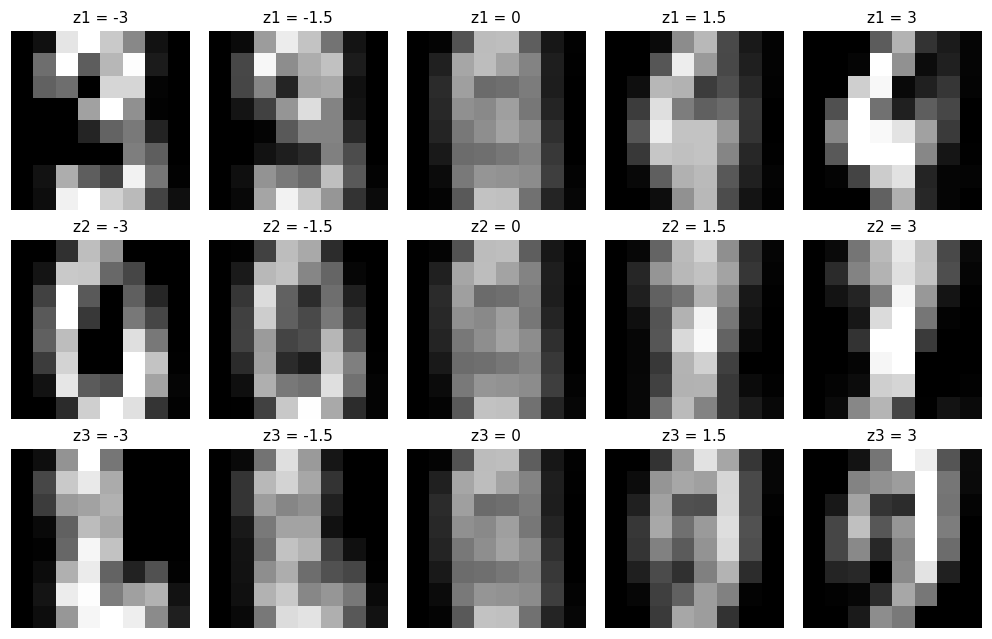

Partie 2 : tous les contrôles ont réussi.


In [5]:
values=[-3.,-1.5,0.,1.5,3.]
fig,ax=plt.subplots(3,5,figsize=(9,5.7),layout='constrained')
for j in range(3):
    for col,val in enumerate(values):
        raw=mu_img+val*np.sqrt(evals[j])*E[:,j]
        ax[j,col].imshow(np.clip(raw,0,1).reshape(8,8),cmap='gray',vmin=0,vmax=1,interpolation='nearest');ax[j,col].axis('off')
        ax[j,col].set_title(f'z{j+1} = {val:g}',fontsize=10)
save(fig,'12_directions_latentes')
metrics={'dataset':'sklearn.load_digits','total_disponible':1797,'N_apprentissage':N,'forme_image':[8,8],'dimension':d,
         'rang_covariance':int(np.sum(evals>1e-10)),
         'variance_conservee':{str(r):float(cumulative[r-1]) for r in [10,25,50]},
         'pixels_hors_intervalle':{str(r):v for r,v in outside.items()},
         'mc_r25':{'N':20000,'erreur_moyenne_L2':mean_err,'erreur_covariance_relative':cov_err}}
Path('metriques_partie2.json').write_text(json.dumps(metrics,ensure_ascii=False,indent=2),encoding='utf-8')
np.savez_compressed('modele_images.npz',moyenne=mu_img,covariance=cov_img,valeurs_propres=evals,vecteurs_propres=E,latents=Z,images_r10=generated[10],images_r25=generated[25],images_r50=generated[50])
print('Partie 2 : tous les contrôles ont réussi.')


## Discussion des limites
Les images générées représentent des variations autour d’un chiffre moyen, souvent avec superposition de traits de classes différentes. La gaussienne unique ne capture pas naturellement une distribution multimodale de chiffres. Les pixels peuvent sortir de leur domaine ; le clipping modifie la loi de génération et masque une partie de cette limite. Augmenter r ajoute de la variation, pas une sémantique de classe. Un générateur non linéaire ou un mélange de modèles peut représenter des formes plus complexes ; ce TP n’entraîne ni GAN ni VAE. Les figures permettent la comparaison visuelle, sans score de qualité perceptuelle ni validation sur le jeu réservé.